# 1.0 Exploración de los datos de MiBici

**Issue:** #12 · **Rama:** `docs/notebook-exploracion`

Objetivo: entender los datos de viajes de MiBici y justificar las decisiones de las siguientes etapas.
Notebook de exploración: las transformaciones definitivas se implementan en los módulos del paquete.

Contenido:
1. Tamaño y calidad de los datos
2. Patrones por día y hora
3. Demanda diaria (insumo para P1)
4. Estaciones
5. Flujo neto por estación y umbral de riesgo (insumo para P2)
6. Conclusiones

In [29]:
from pathlib import Path
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

# El notebook vive en notebooks/, así que la raíz del repo es el padre
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
INTERIM = ROOT / "data" / "interim"
PROCESSED = ROOT / "data" / "processed"

print("Raíz:", ROOT)
for p in (RAW, INTERIM, PROCESSED):
    archivos = sorted(x.name for x in p.glob("*")) if p.exists() else "no existe"
    print(p.relative_to(ROOT), "->", archivos)

Raíz: /home/anaim/TC5061-Proyecto-Equipo03
data/raw -> ['datos_abiertos_2025_10.csv', 'datos_abiertos_2025_11.csv', 'datos_abiertos_2025_12.csv', 'datos_abiertos_2026_01.csv', 'datos_abiertos_2026_02.csv', 'datos_abiertos_2026_03.csv', 'datos_abiertos_2026_04.csv', 'datos_abiertos_2026_05.csv', 'datos_abiertos_2026_06.csv', 'datos_abiertos_2026_07.csv', 'datos_abiertos_2026_08.csv', 'datos_abiertos_2026_09.csv', 'nomenclatura_2026_09.csv']
data/interim -> no existe
data/processed -> no existe


## Carga de datos

Se usan los viajes de octubre de 2025 a septiembre de 2026 (`datos_abiertos_*.csv`) y el catálogo de estaciones (`nomenclatura_*.csv`).
Los encabezados de MiBici traen acentos y mayúsculas, por lo que se normalizan a minúsculas sin acentos.

In [42]:
def normalizar(col: str) -> str:
    col = unicodedata.normalize("NFKD", str(col)).encode("ascii", "ignore").decode()
    return col.strip().lower().replace(" ", "_")


def leer_csv(path: Path) -> pd.DataFrame:
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc, low_memory=False)
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo leer {path}")


csvs = sorted(RAW.glob("datos_abiertos_*.csv"))
print("Archivos:", [p.name for p in csvs])
viajes = pd.concat([leer_csv(p) for p in csvs], ignore_index=True)

viajes.columns = [normalizar(c) for c in viajes.columns]

pd.DataFrame({
    "tipo": viajes.dtypes.astype(str),
    "no_nulos": viajes.notna().sum(),
    "valores_distintos": viajes.nunique(),
})

Archivos: ['datos_abiertos_2025_10.csv', 'datos_abiertos_2025_11.csv', 'datos_abiertos_2025_12.csv', 'datos_abiertos_2026_01.csv', 'datos_abiertos_2026_02.csv', 'datos_abiertos_2026_03.csv', 'datos_abiertos_2026_04.csv', 'datos_abiertos_2026_05.csv', 'datos_abiertos_2026_06.csv', 'datos_abiertos_2026_07.csv', 'datos_abiertos_2026_08.csv', 'datos_abiertos_2026_09.csv']


,tipo,no_nulos,valores_distintos
viaje_id,int64,4497877,4497119
usuario_id,int64,4497877,32562
genero,str,4464895,2
ano_de_nacimiento,float64,4497343,73
inicio_del_viaje,str,4497877,4003674
fin_del_viaje,str,4497877,4010269
origen_id,int64,4497877,471
destino_id,int64,4497877,471


- Los viajes corresponden a 32,562 usuarios distintos y a 471 estaciones de origen y destino.

In [31]:
# Identificar columnas clave aunque cambie el nombre exacto
def buscar(*claves):
    for c in viajes.columns:
        if all(k in c for k in claves):
            return c
    raise KeyError(f"No encontré columna con {claves}. Columnas: {list(viajes.columns)}")

COL_INICIO = buscar("inicio")
COL_FIN = buscar("fin")
COL_ORIGEN = buscar("origen")
COL_DESTINO = buscar("destino")
print(COL_INICIO, COL_FIN, COL_ORIGEN, COL_DESTINO)

inicio_del_viaje fin_del_viaje origen_id destino_id


## 1. Tamaño y calidad

In [32]:
print(f"Filas: {len(viajes):,}  ·  Columnas: {viajes.shape[1]}")
print(f"Memoria: {viajes.memory_usage(deep=True).sum() / 1e6:,.1f} MB")
print(f"Duplicados exactos: {viajes.duplicated().sum():,}")
viajes.isna().mean().mul(100).round(2).rename("% nulos").to_frame()

Filas: 4,497,877  ·  Columnas: 8
Memoria: 463.8 MB
Duplicados exactos: 758


,% nulos
viaje_id,0.00
usuario_id,0.00
genero,0.73
ano_de_nacimiento,0.01
inicio_del_viaje,0.00
fin_del_viaje,0.00
origen_id,0.00
destino_id,0.00


In [33]:
viajes[COL_INICIO] = pd.to_datetime(viajes[COL_INICIO], errors="coerce")
viajes[COL_FIN] = pd.to_datetime(viajes[COL_FIN], errors="coerce")
viajes["duracion_min"] = (viajes[COL_FIN] - viajes[COL_INICIO]).dt.total_seconds() / 60

print("Rango de fechas:", viajes[COL_INICIO].min(), "→", viajes[COL_INICIO].max())
print("Fechas no interpretables:", viajes[COL_INICIO].isna().sum())
viajes["duracion_min"].describe(percentiles=[.01, .05, .5, .95, .99]).round(1)

Rango de fechas: 2025-10-01 00:00:26 → 2026-09-30 23:59:48
Fechas no interpretables: 0


count    4497877.0
mean          11.0
std           10.1
min            0.0
1%             0.2
5%             2.0
50%            9.4
95%           24.5
99%           33.4
max         5920.0
Name: duracion_min, dtype: float64

In [34]:
# Viajes sospechosos: duración negativa, casi nula o mayor a 24 h
sospechosos = (viajes["duracion_min"] <= 1) | (viajes["duracion_min"] > 24 * 60)
print(f"Viajes sospechosos: {sospechosos.sum():,} ({sospechosos.mean():.2%})")

v = viajes[~sospechosos & viajes[COL_INICIO].notna()].copy()
v["fecha"] = v[COL_INICIO].dt.date
v["hora"] = v[COL_INICIO].dt.hour
v["dia_semana"] = v[COL_INICIO].dt.dayofweek  # 0 = lunes
print(f"Viajes para explorar: {len(v):,}")

Viajes sospechosos: 159,127 (3.54%)
Viajes para explorar: 4,338,750


## 2. Patrones por día y hora

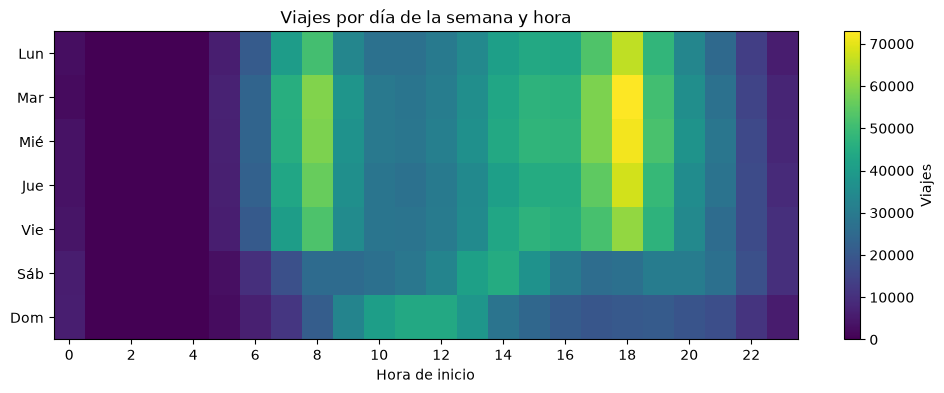

In [35]:
dias = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
tabla = v.pivot_table(index="dia_semana", columns="hora", values=COL_ORIGEN, aggfunc="size", fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(tabla, aspect="auto", cmap="viridis")
ax.set_yticks(range(7), dias)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hora de inicio")
ax.set_title("Viajes por día de la semana y hora")
fig.colorbar(im, ax=ax, label="Viajes")
plt.show()

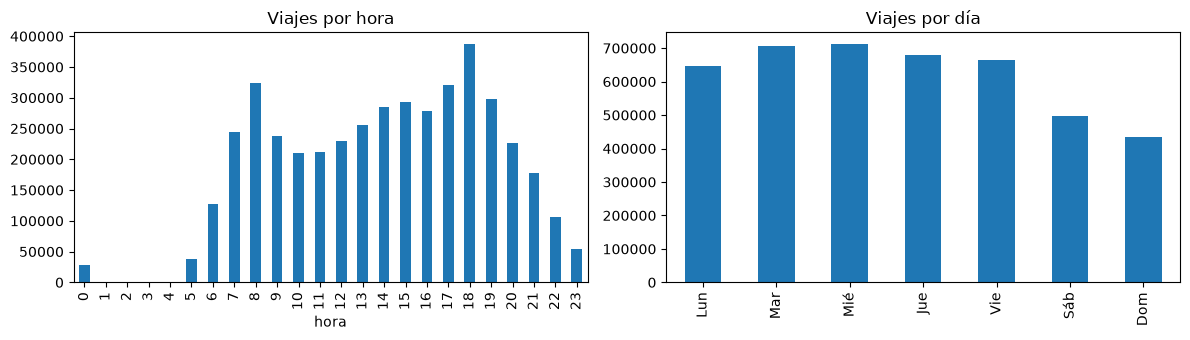

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
v.groupby("hora").size().plot.bar(ax=axes[0], title="Viajes por hora")
v.groupby("dia_semana").size().set_axis(dias).plot.bar(ax=axes[1], title="Viajes por día")
plt.tight_layout(); plt.show()

## 3. Demanda diaria (P1)

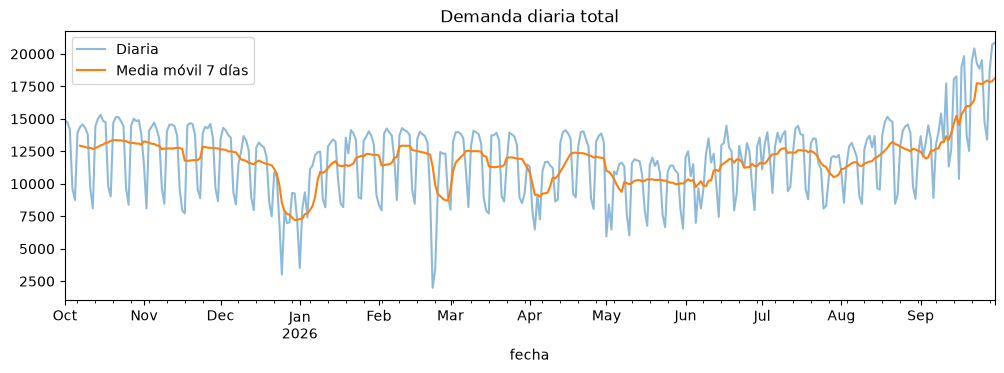

count      365.0
mean     11887.0
std       2909.0
min       1992.0
25%       9372.0
50%      12498.0
75%      13856.0
max      20857.0
Name: viajes, dtype: float64

In [37]:
diaria = v.groupby("fecha").size().rename("viajes")
diaria.index = pd.to_datetime(diaria.index)

ax = diaria.plot(figsize=(12, 3.5), alpha=.5, label="Diaria")
diaria.rolling(7).mean().plot(ax=ax, label="Media móvil 7 días")
ax.set_title("Demanda diaria total"); ax.legend(); plt.show()

diaria.describe().round(0)

## 4. Estaciones

In [38]:
salidas = v.groupby(COL_ORIGEN).size().rename("salidas")
llegadas = v.groupby(COL_DESTINO).size().rename("llegadas")
estaciones = pd.concat([salidas, llegadas], axis=1).fillna(0).astype(int)
estaciones["total"] = estaciones.sum(axis=1)

# Catálogo de estaciones, si está en data/raw (archivo de nomenclatura de MiBici)
cat = sorted(RAW.glob("*nomenclatura*.csv"))
if cat:
    catalogo = leer_csv(cat[0])
    catalogo.columns = [normalizar(c) for c in catalogo.columns]
    estaciones = estaciones.join(catalogo.set_index("id")[["name"]], how="left")

print("Estaciones con actividad:", len(estaciones))
print("\nMás usadas:"); display(estaciones.nlargest(10, "total"))
print("Menos usadas:"); display(estaciones.nsmallest(10, "total"))

Estaciones con actividad: 471

Más usadas:


,salidas,llegadas,total,name
51,91977,107286,199263,(GDL-049) Lopez Cotilla / Penitenciaría
35,72422,84934,157356,(GDL-033) Av. Hidalgo / C. Pedro Loza
271,67446,58821,126267,(GDL-198) Av. Alcalde / C. Hospital
11,61461,56069,117530,(GDL-009) Calz. Federalismo/ C. J. Angulo
50,50842,52045,102887,(GDL-048) C. Constancio Hernández/ Av. Juaréz
52,50207,47935,98142,(GDL-050) C.Pedro Moreno /Federalismo
54,47794,49892,97686,(GDL-052) Av. Juarez /16 de Septiembre
260,37424,44700,82124,(GDL-187) Av. 16 de Septiembre / C. Priscilia
38,39405,39955,79360,(GDL-036) C. Marcos Castellanos/ C. Morelos
194,50325,23128,73453,(GDL-127) Av. Vallarta / Av. de Los Arcos


Menos usadas:


,salidas,llegadas,total,name
405,2,2,4,NaN
511,112,87,199,(ZPN-094) Av. V. el Colli / C. V. Paricutín
465,122,121,243,(GDL-335) Dionisio Rdgz/González Bocanegra
514,152,142,294,(ZPN-101) C. Volcán Quinceo/C. Ignacio C.
510,173,180,353,(ZPN-102) C. Volcán del Colli/V. del Ajusco
509,170,184,354,(ZPN-100) C. Popocatépetl / C. Volcán Barú
508,213,164,377,(ZPN-099) C. Playa Olas / Av. El Colli
433,274,141,415,(ZPN-089) C. Arquitectos/Av. San Luis Gonzaga
488,224,219,443,(ZPN-083) C. Playa de Hornos / C. Playa Oro
462,278,267,545,(GDL-328) Gral. P. M.Anaya / Basilio Vadillo


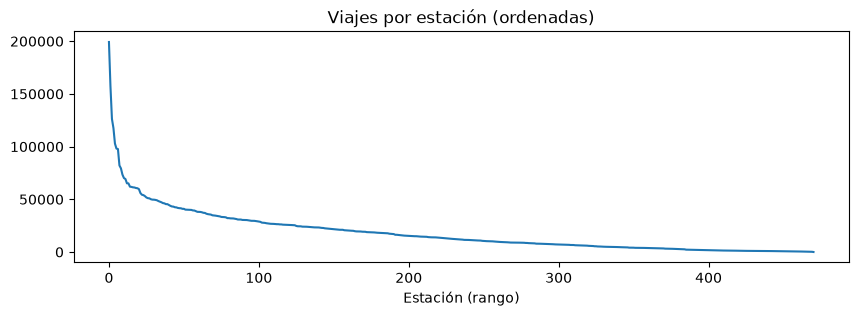

El 20% de estaciones concentra 55% de los viajes


In [39]:
ax = estaciones["total"].sort_values(ascending=False).reset_index(drop=True).plot(figsize=(10, 3))
ax.set_title("Viajes por estación (ordenadas)"); ax.set_xlabel("Estación (rango)"); plt.show()

top20 = estaciones.nlargest(int(len(estaciones) * .2), "total")["total"].sum() / estaciones["total"].sum()
print(f"El 20% de estaciones concentra {top20:.0%} de los viajes")

## 5. Flujo neto y umbral de riesgo (P2)

Flujo neto por estación y hora = llegadas − salidas.
Un flujo muy negativo indica que la estación se vacía; muy positivo, que se llena.
El umbral se justifica con los percentiles de la distribución.
El umbral de riesgo se define a partir de los percentiles de esta distribución.

0.01   -6.0
0.05   -3.0
0.10   -2.0
0.50    0.0
0.90    2.0
0.95    3.0
0.99    6.0
Name: neto, dtype: float64


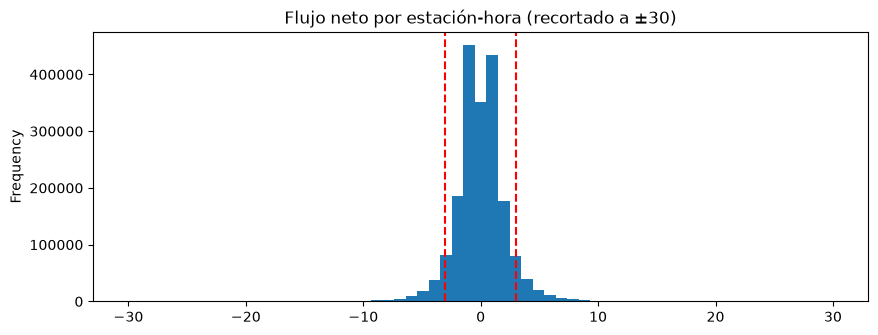

In [40]:
v["hora_redondeada"] = v[COL_INICIO].dt.floor("h")
v["hora_llegada"] = v[COL_FIN].dt.floor("h")

sal = v.groupby([COL_ORIGEN, "hora_redondeada"]).size().rename("salidas")
lle = v.groupby([COL_DESTINO, "hora_llegada"]).size().rename("llegadas")
sal.index.names = lle.index.names = ["estacion", "hora"]

flujo = pd.concat([sal, lle], axis=1).fillna(0)
flujo["neto"] = flujo["llegadas"] - flujo["salidas"]

pct = flujo["neto"].quantile([.01, .05, .10, .50, .90, .95, .99])
print(pct)

ax = flujo["neto"].clip(-30, 30).plot.hist(bins=61, figsize=(10, 3.5))
for q in (.05, .95):
    ax.axvline(pct[q], color="red", ls="--")
ax.set_title("Flujo neto por estación-hora (recortado a ±30)"); plt.show()

In [41]:
umbral = pct[.05]  # propuesta inicial: percentil 5
riesgo = flujo["neto"] <= umbral
print(f"Umbral propuesto: flujo neto ≤ {umbral:.0f} bicis/hora")
print(f"Estación-horas en riesgo: {riesgo.sum():,} ({riesgo.mean():.1%})")

Umbral propuesto: flujo neto ≤ -3 bicis/hora
Estación-horas en riesgo: 159,680 (8.3%)


## 6. Conclusiones

**Tamaño y calidad**
- Se analizaron 4,497,877 viajes de octubre de 2025 a septiembre de 2026 (12 meses), con 8 columnas y 464 MB en memoria.
- La calidad es buena: las fechas se interpretan correctamente y solo `genero` (0.73 %) y `ano_de_nacimiento` (0.01 %) tienen nulos.
- Hay 758 registros duplicados exactos, la misma cantidad que en julio a septiembre, por lo que todos se concentran en esos meses. Deben eliminarse en la limpieza.
- La duración mediana es de 9.4 minutos y el 95 % de los viajes dura menos de 25 minutos. Se descartó el 3.5 % (159,127 viajes) por durar 1 minuto o menos, lo que sugiere viajes cancelados, o más de 24 horas, lo que sugiere bicicletas no devueltas a tiempo (el máximo fue de 5,920 minutos). Quedan 4,338,750 viajes para el análisis.

**Patrones**
- Entre semana el uso sigue un patrón de traslado al trabajo o la escuela, con dos picos: 8:00 (cerca de 325 mil viajes) y 18:00, la hora con más viajes del año (cerca de 385 mil). Entre ambos hay un valle a las 10:00 y 11:00.
- Prácticamente no hay viajes entre la 1:00 y las 4:00, lo que sugiere que el sistema no opera en ese horario.
- El fin de semana desaparecen los picos de traslado y la demanda se concentra al mediodía, sobre todo los domingos entre las 10:00 y las 14:00, lo que indica un uso más recreativo.
- De lunes a viernes hay entre 645 y 710 mil viajes por día de la semana, con martes y miércoles como los más altos. El sábado (≈495 mil) y el domingo (≈435 mil) tienen cerca de 30 % menos.
- La hora y el día de la semana son variables clave para P1 y P2.

**Demanda diaria (P1)**
- Se registran 11,887 viajes por día en promedio, con una desviación estándar de 2,909 (cerca del 25 % del promedio). La mitad de los días tiene entre 9,372 y 13,856 viajes.
- El día con más viajes llegó a 20,857, y el de menos solo a 1,992, un valor muy por debajo del resto que probablemente corresponde a un día festivo o a una interrupción del servicio.
- Esta variación justifica incluir en P1 variables de calendario como día de la semana, mes y días festivos, y tratar los días atípicos por separado.

**Estaciones**
- Hay 471 estaciones con actividad y el uso está concentrado: el 20 % de las estaciones genera el 55 % de los viajes.
- Las 10 más usadas están en el centro de Guadalajara (prefijo GDL), encabezadas por López Cotilla / Penitenciaría con 199,263 viajes.
- Varias de las menos usadas, en Zapopan (ZPN), solo registran viajes desde julio de 2026, lo que indica que son estaciones nuevas. Su bajo total refleja menos tiempo en operación, no necesariamente baja demanda, por lo que en P1 y P3 conviene comparar estaciones por viajes por día activo.
- La estación 405 tiene viajes pero no aparece en el catálogo de septiembre de 2026, por lo que probablemente fue retirada. Se deben revisar las altas y bajas de estaciones en la ingesta.

**Umbral de riesgo (P2)**
- El flujo neto por estación y hora (llegadas − salidas) se centra en 0, y el 90 % de los casos está entre −3 y +3 bicicletas por hora.
- Se propone un umbral de riesgo de flujo neto ≤ −3 bicicletas por hora (percentil 5), que identifica las horas en que una estación pierde bicicletas de forma inusual.
- Con este umbral, el 8.3 % de las estación-horas (159,680) se clasifica en riesgo. El porcentaje es mayor al 5 % porque el flujo toma valores enteros y muchos casos caen justo en −3.